# 01 · Data understanding and EDA
**Problem.** Forecast district-level paddy yield (kg/ha) for a Maha or Yala season *before harvest*, from seasonal weather, irrigation context and recent yield history. Users: Department of Agriculture / Paddy Marketing Board / food-security planners who need early warning of low-yield seasons for stock and import decisions.

**Data**
| Source | Content | Coverage |
|---|---|---|
| Dept. of Census & Statistics (DCS) | District average yield, production, sown and harvested extent | Maha + Yala, 1979–2025 |
| Open-Meteo historical API (ERA5) | Daily rain, Tmax, Tmin, FAO-56 ET0 at one paddy-area point per district | 1979–present |
| NOAA CPC | Oceanic Niño Index (ENSO) | 1950–present |

One row = one district × one season. Built by `python -m src.features`.

In [2]:
import sys, warnings
sys.path.insert(0, "..")
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
from src.features import TARGET, WEATHER_FEATURES, HISTORY_FEATURES, FEATURE_DESCRIPTIONS, feature_list

df = pd.read_csv(C.PROCESSED / "model_table.csv")
sns.set_theme(style="whitegrid", context="notebook")
FIG = C.FIGURES
print(df.shape)
df.head()

(2249, 28)


,district,season,season_year,harvested_ha,production_mt,sown_ha,yield_kg_ha,rain_total,rain_establish,rain_late,...,water_balance,rain_anom_pct,t,prev_yield_same,yield_mean3_same,yield_mean5_same,sown_change_pct,prev_yield_any,fertilizer_crisis,oni_mean
0,Ampara,Maha,1978,41779.0,29300.0,44037.0,3124.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
1,Anuradhapura,Maha,1978,72864.0,207000.0,75060.0,3528.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
2,Badulla,Maha,1978,16100.0,27500.0,16337.0,3091.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
3,Batticaloa,Maha,1978,38896.0,27700.0,46002.0,2364.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667
4,Colombo,Maha,1978,7059.0,12200.0,7270.0,2038.0,NaN,NaN,NaN,...,NaN,NaN,1978.75,NaN,NaN,NaN,NaN,NaN,0,0.076667


## 1. Structure, types and coverage

In [3]:
print(f"{df.district.nunique()} districts, seasons {df.season_year.min()}-{df.season_year.max()}")
print(df.groupby("season").size().rename("rows"))
df.info()

25 districts, seasons 1978-2025
season
Maha    1153
Yala    1096
Name: rows, dtype: int64
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2249 entries, 0 to 2248
Data columns (total 28 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   district            2249 non-null   object 
 1   season              2249 non-null   object 
 2   season_year         2249 non-null   int64  
 3   harvested_ha        2249 non-null   float64
 4   production_mt       2190 non-null   float64
 5   sown_ha             2249 non-null   float64
 6   yield_kg_ha         2249 non-null   float64
 7   rain_total          1868 non-null   float64
 8   rain_establish      1868 non-null   float64
 9   rain_late           1868 non-null   float64
 10  rain_days           1868 non-null   float64
 11  rain_max5d          1868 non-null   float64
 12  longest_dry_spell   1868 non-null   float64
 13  tmax_mean           1868 non-null   float64
 14  tmin_mean     

In [4]:
df[[TARGET, "sown_ha", "harvested_ha", "production_mt"] + WEATHER_FEATURES].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
yield_kg_ha,2249.0,3537.3,841.4,1153.0,2936.0,3499.0,4089.0,6622.0
sown_ha,2249.0,19201.2,19148.0,12.0,6863.0,13092.0,21201.0,127517.0
harvested_ha,2249.0,18296.0,18510.3,11.0,6424.0,12578.0,20171.0,127203.0
production_mt,2190.0,61636.4,73409.5,100.0,18200.0,35700.0,66982.5,530360.0
rain_total,1868.0,894.7,447.1,35.0,538.0,857.6,1211.4,2605.6
rain_establish,1868.0,421.4,233.1,5.9,245.0,391.8,562.6,1521.0
rain_late,1868.0,151.2,121.2,0.0,64.0,118.6,205.9,795.8
rain_days,1868.0,106.4,36.4,12.0,81.0,104.0,127.0,182.0
rain_max5d,1868.0,128.0,72.6,10.7,82.9,112.6,151.9,657.2
longest_dry_spell,1868.0,16.3,12.2,1.0,8.0,13.0,21.0,95.0


In [5]:
pd.DataFrame({f: FEATURE_DESCRIPTIONS.get(f, "") for f in feature_list(df)}, index=["description"]).T

,description
district,District (categorical)
season,"Maha (Oct-Mar, NE monsoon) or Yala (Apr-Sep, S..."
season_year,Year the season starts - captures the long-run...
fertilizer_crisis,1 for Maha 2021/22 and Yala 2022 (fertilizer i...
prev_yield_same,District yield in the previous season of the s...
prev_yield_any,District yield in the immediately preceding se...
yield_mean3_same,Mean district yield over the last 3 seasons of...
sown_ha,Gross extent sown this season (ha) - known at ...
sown_change_pct,% change in sown extent vs previous same-type ...
rain_total,Total rainfall in the 6-month season window (mm)


## 2. Missing values
Northern districts have gaps during the conflict years (and Kilinochchi / Mullaitivu were only reported separately later). Lag features are missing for each district's first seasons by construction.

,missing_share
antecedent_rain_6m,0.178
rain_days,0.169
rain_max5d,0.169
tmax_mean,0.169
rain_establish,0.169
rain_late,0.169
rain_total,0.169
longest_dry_spell,0.169
water_balance,0.169
tmin_mean,0.169


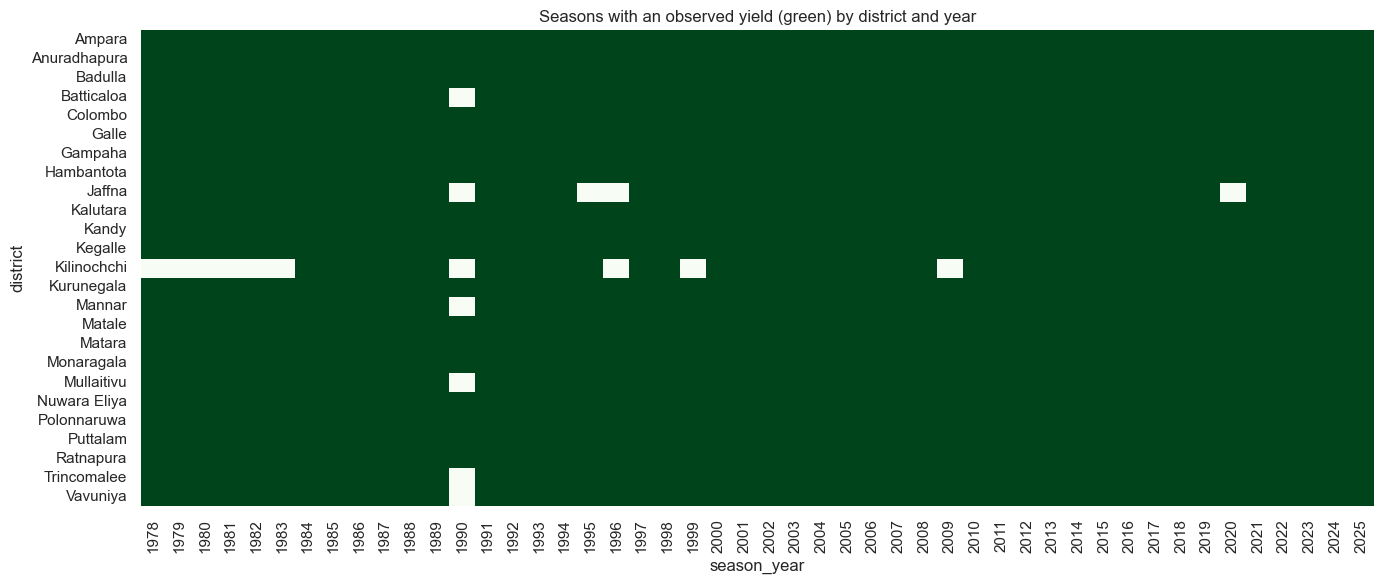

In [6]:
miss = df[feature_list(df) + [TARGET]].isna().mean().sort_values(ascending=False)
display(miss[miss > 0].to_frame("missing_share").round(3))

grid = (df.pivot_table(index="district", columns="season_year", values=TARGET, aggfunc="count")
          .reindex(sorted(C.DISTRICTS)))
plt.figure(figsize=(14, 6))
sns.heatmap(grid.notna() & (grid > 0), cbar=False, cmap="Greens")
plt.title("Seasons with an observed yield (green) by district and year")
plt.tight_layout(); plt.savefig(FIG / "eda_missing_map.png", dpi=150); plt.show()

**Observations.**

- About 17% of rows have no weather. Almost all of it comes from four districts that have no weather file at all: Ratnapura and Kegalle (94 rows each), Mannar (87) and Vavuniya (86). Every other district is missing weather only for Maha 1978, the first season in the table.
- `antecedent_rain_6m` is missing slightly more often (17.8%) because it looks back six months before the season starts, so Yala 1979 has no value either.
- The lag features (`prev_yield_*`, `yield_mean3_same`, `sown_change_pct`) are 3.5 to 5% missing. These are each district's first seasons, plus the season after any gap in the record.
- The map shows the gaps are concentrated in the north and east. 1990 is missing for Jaffna, Mullaitivu, Mannar, Vavuniya, Batticaloa and Trincomalee. Kilinochchi only starts in 1984 and has further holes in 1990, 1996, 1999 and 2009. Jaffna is the thinnest district, with 49 rows, and only 5 of them are Yala.
- Maha 2020 has no rows for any district, so that whole season is absent from the target.

## 3. Target: yield distribution and trend

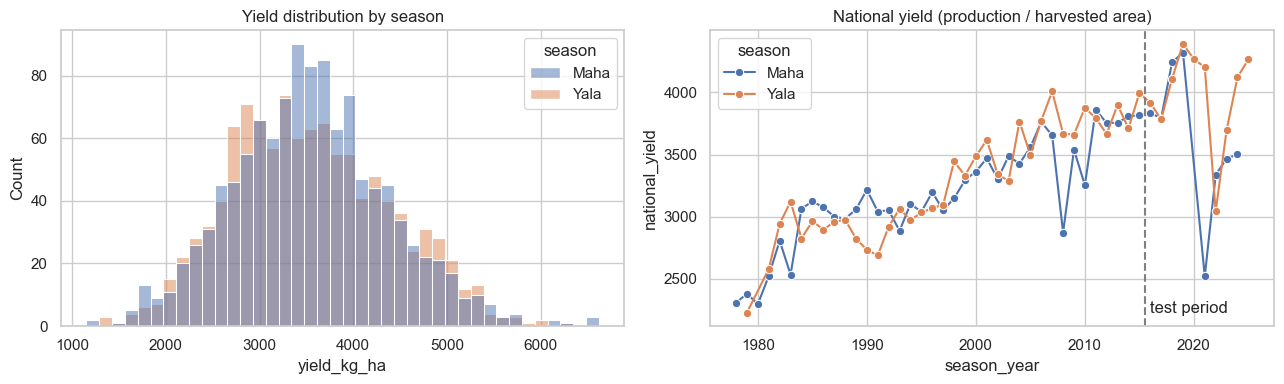

skewness: 0.25


In [7]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(df, x=TARGET, hue="season", bins=40, ax=ax[0])
ax[0].set_title("Yield distribution by season")
nat = (df.dropna(subset=["production_mt"]).groupby(["season_year", "season"])
         .apply(lambda g: 1000 * g.production_mt.sum() / g.harvested_ha.sum()).rename("national_yield").reset_index())
sns.lineplot(nat, x="season_year", y="national_yield", hue="season", marker="o", ax=ax[1])
ax[1].axvline(C.TRAIN_END + 0.5, ls="--", c="grey"); ax[1].text(C.TRAIN_END + 1, nat.national_yield.min(), "test period")
ax[1].set_title("National yield (production / harvested area)")
plt.tight_layout(); plt.savefig(FIG / "eda_target.png", dpi=150); plt.show()
print("skewness:", df[TARGET].skew().round(2))

**Observations.**

- Maha and Yala yields have almost the same distribution: medians of 3,518 and 3,474 kg/ha, with standard deviations of about 830 and 855. Skewness is 0.25, close enough to symmetric that the target can be modelled without a log transform.
- National yield has risen steadily, from about 2,300 kg/ha in the late 1970s to about 4,300 kg/ha in 2019. Because of this trend, `season_year` and the lag features will carry much of the signal.
- The clearest drops are Maha 2008 (2,872 kg/ha, down from 3,654 the season before) and the fertilizer import ban: Maha 2021/22 fell to 2,521 and Yala 2022 to 3,043. Yields recovered in 2023 and 2024 but are still below the 2019 peak.
- The test period starts in 2016, so it contains the fertilizer crisis. That makes the test set harder than a random split would be, and closer to how the model would be used in practice.
- The national line has no point for Maha 2020 (no rows) or Maha 2025 (production not yet reported).

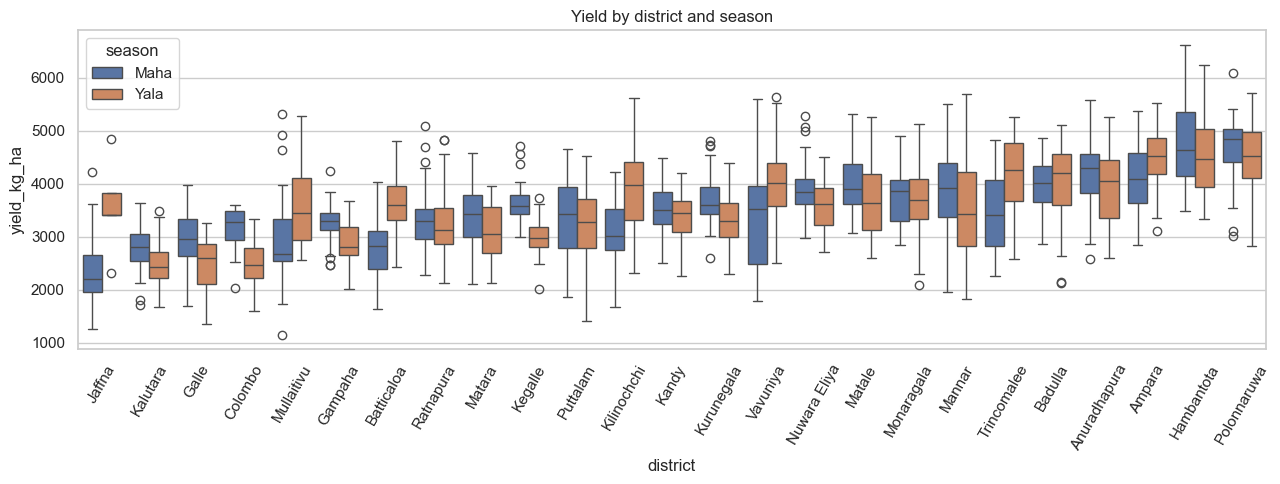

In [8]:
order = df.groupby("district")[TARGET].median().sort_values().index
plt.figure(figsize=(13, 5))
sns.boxplot(df, x="district", y=TARGET, hue="season", order=order)
plt.xticks(rotation=60); plt.title("Yield by district and season")
plt.tight_layout(); plt.savefig(FIG / "eda_district_box.png", dpi=150); plt.show()

**Observations.**

- District matters more than season. The irrigated dry-zone districts have the highest medians: Polonnaruwa (4,731 kg/ha), Hambantota (4,588), Ampara (4,292) and Anuradhapura (4,158). The lowest are Jaffna (2,246) and the wet-zone south-west: Kalutara (2,646), Galle (2,678) and Colombo (2,922). The roughly 2,500 kg/ha gap between the top and bottom is far larger than the gap between seasons.
- The season effect changes sign by region. In the north and east, Yala yields are higher (Jaffna by about 1,200 kg/ha, Kilinochchi by 950, Trincomalee by 860). In the wet zone, Maha is higher (Colombo by about 800, Kegalle by 600). The two cancel out nationally, which is why the season histograms overlap. The model needs to learn a district by season interaction.
- Year-to-year variability also differs. The coefficient of variation is about 0.13 in Kandy, Nuwara Eliya, Gampaha and Polonnaruwa, but 0.24 to 0.26 in Kilinochchi, Mannar, Vavuniya and Mullaitivu, and 0.30 in Jaffna. Expect larger forecast errors in the northern districts.

## 4. Outliers
IQR rule within each district × season. These are *real* shocks (droughts, floods, policy), not data errors, so they are kept — removing them would teach the model that bad seasons never happen.

In [9]:
def iqr_flags(g):
    q1, q3 = g[TARGET].quantile([.25, .75]); iqr = q3 - q1
    return (g[TARGET] < q1 - 1.5 * iqr) | (g[TARGET] > q3 + 1.5 * iqr)
df["iqr_outlier"] = df.groupby(["district", "season"], group_keys=False).apply(iqr_flags)
print(f"{df.iqr_outlier.sum()} outlier rows ({100 * df.iqr_outlier.mean():.1f}%)")
df[df.iqr_outlier].sort_values(TARGET)[["district", "season", "season_year", TARGET, "rain_anom_pct", "fertilizer_crisis"]].head(15)

41 outlier rows (1.8%)


,district,season,season_year,yield_kg_ha,rain_anom_pct,fertilizer_crisis
256,Mullaitivu,Maha,1983,1153.0,73.939177,0
9,Kalutara,Maha,1978,1707.0,NaN,0
56,Kalutara,Maha,1979,1803.0,7.818491,0
35,Kegalle,Yala,1979,2012.0,NaN,0
4,Colombo,Maha,1978,2038.0,NaN,0
87,Monaragala,Yala,1980,2084.0,3.028995,0
73,Badulla,Yala,1980,2134.0,1.552822,0
121,Badulla,Yala,1981,2146.0,5.797399,0
32,Jaffna,Yala,1979,2318.0,-20.614165,0
53,Gampaha,Maha,1979,2473.0,18.509834,0


**Observations.**

- 41 rows (1.8%) are flagged: 17 low and 24 high. Most of them reflect the long-run trend: the low flags cluster in 1978 to 1983 and the high flags in 2012 onward, especially 2017 to 2019, because a fixed per-district IQR ignores the steady rise in yield.
- The fertilizer crisis barely shows up. Only Polonnaruwa Maha 2021 is flagged (3,103 kg/ha against a district median of 4,848), because a 2021 drop lands back among the district's older yields. Comparing each season with the previous-5 mean, as in section 5, picks out real shocks better.
- The single lowest value is Mullaitivu Maha 1983 at 1,153 kg/ha.
- All flagged rows are kept, as explained above.

## 5. Weather vs yield

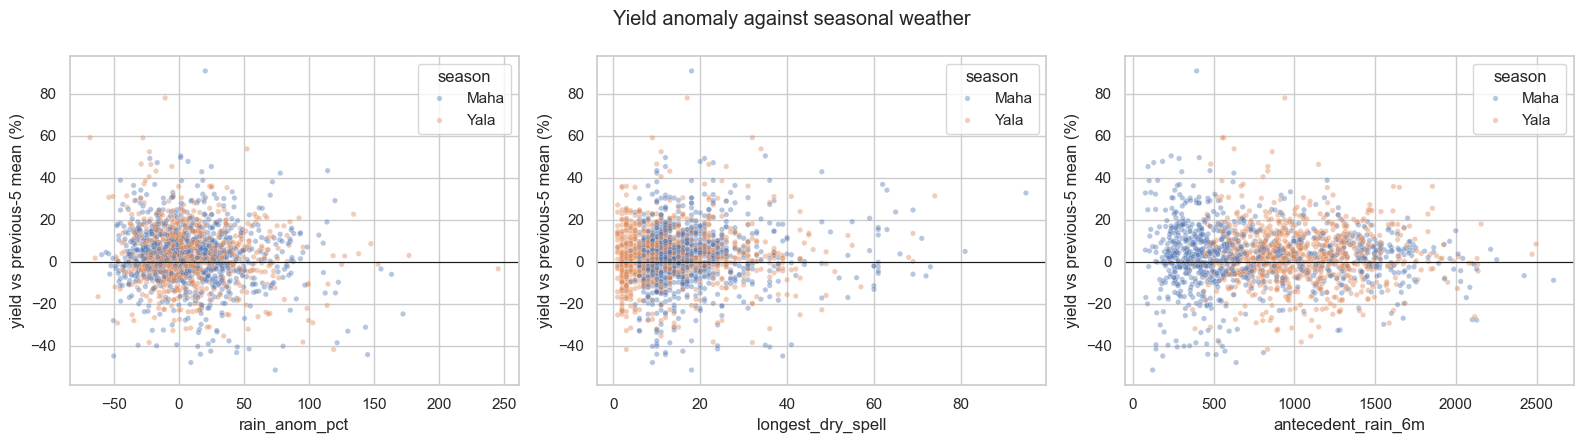

In [10]:
df["yield_anom_pct"] = 100 * (df[TARGET] / df["yield_mean5_same"] - 1)
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for a, f in zip(ax, ["rain_anom_pct", "longest_dry_spell", "antecedent_rain_6m"]):
    sns.scatterplot(df, x=f, y="yield_anom_pct", hue="season", alpha=.4, s=15, ax=a)
    a.axhline(0, c="k", lw=.8); a.set_ylabel("yield vs previous-5 mean (%)")
plt.suptitle("Yield anomaly against seasonal weather"); plt.tight_layout()
plt.savefig(FIG / "eda_weather_scatter.png", dpi=150); plt.show()

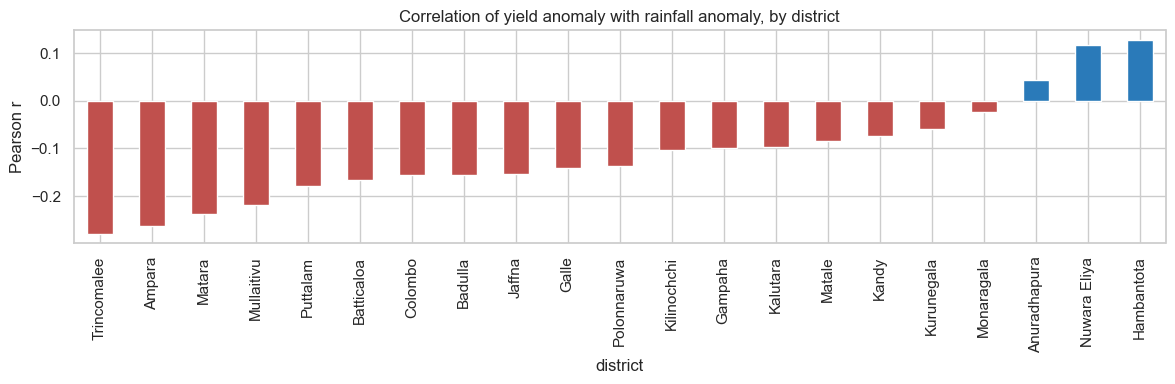

In [11]:
sens = (df.dropna(subset=["yield_anom_pct", "rain_anom_pct"]).groupby("district")
          .apply(lambda g: g["yield_anom_pct"].corr(g["rain_anom_pct"])).sort_values())
plt.figure(figsize=(12, 4)); sens.plot.bar(color=np.where(sens > 0, "#2a7ab9", "#c0504d"))
plt.title("Correlation of yield anomaly with rainfall anomaly, by district"); plt.ylabel("Pearson r")
plt.tight_layout(); plt.savefig(FIG / "eda_rain_sensitivity.png", dpi=150); plt.show()

**Observations.**

- Seasonal weather has a weak relationship with the yield anomaly. Pearson r is -0.11 for `rain_anom_pct`, 0.06 for `longest_dry_spell` and -0.05 for `antecedent_rain_6m`, and the scatter clouds sit around zero.
- Too much rain seems to hurt more than too little. Seasons with rainfall more than 60% above normal average -0.6% against the previous-5 mean, compared with about +3% for near-normal seasons. Very dry seasons (more than 40% below normal) average +2.8%, so there is no drought penalty on average. One possible reason is that most paddy area is irrigated, which buffers low rainfall but not flooding.
- By district, the correlation is negative almost everywhere. It is strongest in the east and north-east (Trincomalee -0.28, Ampara -0.26) and in Matara (-0.24). Only Anuradhapura, Nuwara Eliya and Hambantota are slightly positive. The chart shows 21 districts because the four without weather data are left out.
- Weather on its own will not drive the forecast. It is more likely to help in the few extreme seasons than in typical ones.

## 6. Correlations and multicollinearity

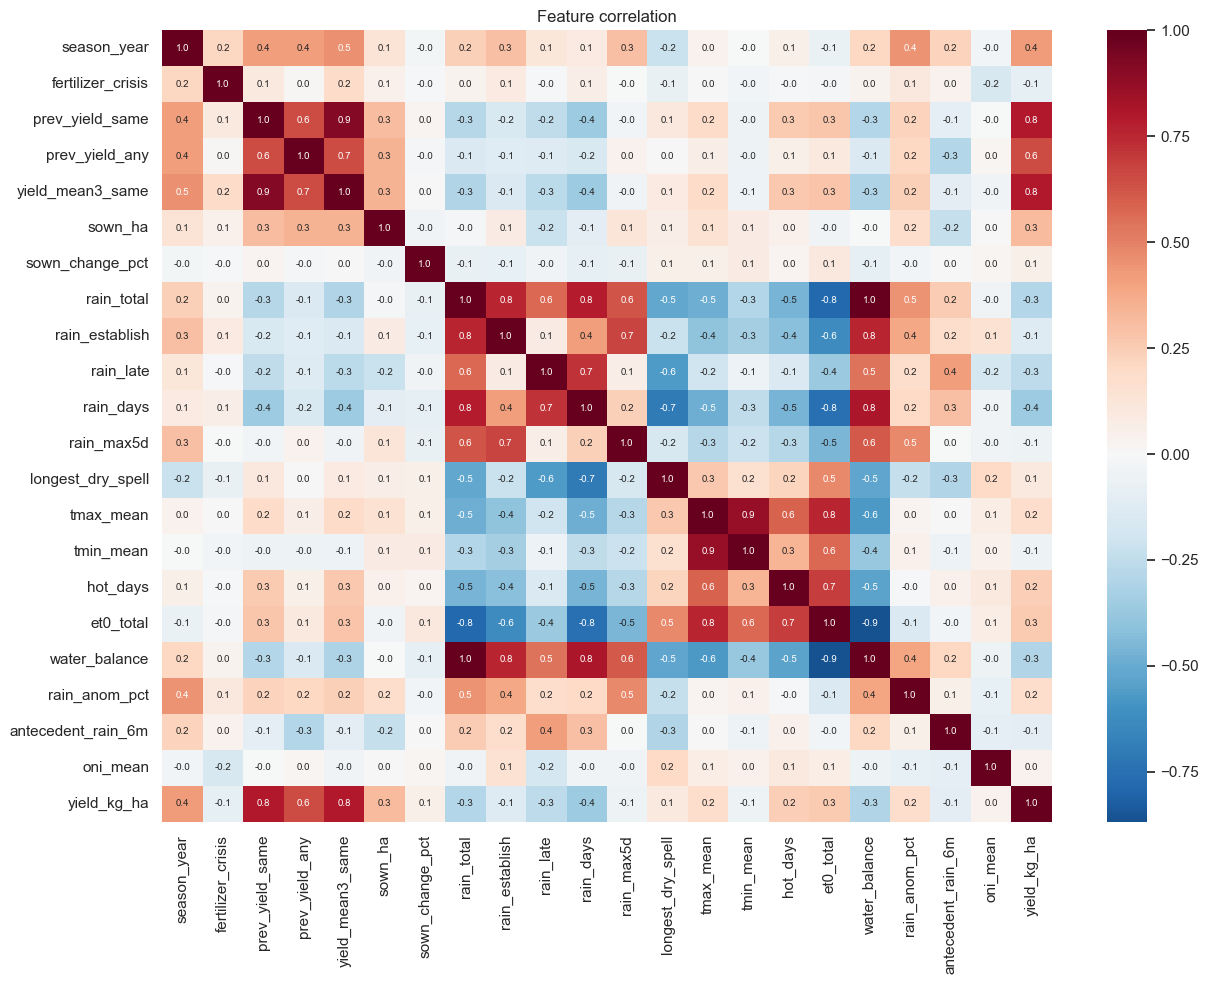

,,|r|
rain_total,water_balance,0.988025
prev_yield_same,yield_mean3_same,0.916638
et0_total,water_balance,0.867571
tmax_mean,tmin_mean,0.865059
rain_days,water_balance,0.811913
prev_yield_same,yield_kg_ha,0.801392


In [12]:
num = [f for f in feature_list(df) if f not in ("district", "season")] + [TARGET]
corr = df[num].corr()
plt.figure(figsize=(13, 10))
sns.heatmap(corr, cmap="RdBu_r", center=0, annot=True, fmt=".1f", annot_kws={"size": 7})
plt.title("Feature correlation"); plt.tight_layout(); plt.savefig(FIG / "eda_corr.png", dpi=150); plt.show()
pairs = (corr.where(np.triu(np.ones(corr.shape, bool), 1)).stack().abs().sort_values(ascending=False))
pairs[pairs > .8].to_frame("|r|")

**Observations.**

- The features most correlated with yield are all history: `prev_yield_same` (0.80), `yield_mean3_same` (0.80), `prev_yield_any` (0.65) and `season_year` (0.43).
- Rainfall features are negatively correlated with yield *level* (`rain_days` -0.36, `rain_total` -0.30), but almost uncorrelated with the yield *anomaly* (-0.08 and -0.09). The level correlation reflects differences between districts: wet-zone districts get more rain and also have lower yields. It does not mean more rain lowers yield within a district.
- Several pairs are close to redundant: `rain_total` and `water_balance` (0.99), `prev_yield_same` and `yield_mean3_same` (0.92), `et0_total` and `water_balance` (0.87), `tmax_mean` and `tmin_mean` (0.87), and `rain_days` and `water_balance` (0.81). Tree models can cope with this, but a linear model needs regularisation or one feature from each pair dropped. Importance scores will also be split between correlated features, which matters when interpreting them later.
- `fertilizer_crisis` has the strongest correlation with the yield anomaly (-0.34), even though it covers only two seasons.

## 7. EDA FINAL Suggesetions
1. Yield is driven mainly by district and by a long upward trend. History features (previous yield, 3-season mean, year) are the strongest predictors, and district also changes how Maha and Yala compare.
2. Seasonal weather is a weak signal on average. Its clearest effect is that very wet seasons tend to underperform. Raw rainfall totals mostly encode which district a row belongs to, so they should be read with that in mind.
3. The data has gaps. Four districts (Ratnapura, Kegalle, Mannar, Vavuniya) have no weather data, the conflict years leave holes in the north and east, and Maha 2020 is absent. Northern districts are also the most variable, so they are where the largest errors are expected.
4. The 2016+ test period includes the 2021/22 fertilizer shock, a large drop that the history features cannot anticipate. Outliers are kept because they are real seasons, and per-district IQR flags mostly reflect the trend rather than one-off shocks.